# Matrices of the third-order shear deformation theory

A finite element or Ritz model of the third-order shear deformation theory
(TSDT) needs the constitutive matrix of all its generalized strains. This
example assembles that $13 \times 13$ matrix from the matrices of a
`Laminate` and verifies it against the strain energy integrated ply by ply
through the thickness, see
[Laminate stiffness and plate theories](../constitutive_matrices.rst).

## Theory

In the TSDT of Reddy [1] the in-plane displacements have a cubic term in $z$,
chosen such that the transverse shear strains vanish at the faces, and the
strains are written with the generalized strains of the reference surface,

$$
\varepsilon = \varepsilon^{(0)} + z \varepsilon^{(1)} + z^3
\varepsilon^{(3)}, \qquad \gamma = \gamma^{(0)} + z^2 \gamma^{(2)},
$$

with $\varepsilon = \{\varepsilon_{xx}, \varepsilon_{yy}, \gamma_{xy}\}$ and
$\gamma = \{\gamma_{yz}, \gamma_{xz}\}$. The strain energy per unit area is

$$
U = \frac{1}{2} \sum_k \int_{z_k}^{z_{k+1}} \left( \varepsilon^T C^{(k)}
\varepsilon + \gamma^T C_s^{(k)} \gamma \right) dz = \frac{1}{2} e^T K e,
$$

where, substituting the strains, $K$ collects the integrals
$(A, B, D, E, F, H) = \sum_k \int C^{(k)} (1, z, z^2, z^3, z^4, z^6) dz$ and
$(\bar{A}_{ts}, D_{ts}, F_{ts}) = \sum_k \int C_s^{(k)} (1, z^2, z^4) dz$ in the
layout of the section "Assembling the matrices in a model" of
[Laminate stiffness and plate theories](../constitutive_matrices.rst). The
TSDT satisfies the traction-free conditions at the faces and uses the
uncorrected $\bar{A}_{ts}$, not the corrected `Ats` of the FSDT.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate

def print_table(rows):
    """Print each result, its reference value and their relative difference

    ``rows`` holds ``(name, value, reference)`` or ``(name, value, reference,
    scale)``; the difference is divided by ``scale``, by default the absolute
    value of the reference, e.g. the largest term of the matrix when the
    reference is zero.
    """
    print('%-36s %14s %14s %10s' % ('quantity', 'composites', 'reference',
                                    'rel. diff.'))
    for row in rows:
        name, value, ref = row[:3]
        scale = row[3] if len(row) > 3 else abs(ref)
        print('%-36s % 14.6e % 14.6e %10.1e' % (name, value, ref,
                                               abs(value - ref)/scale))

## Assembling the constitutive matrix

The laminate is unsymmetric and has an offset, so that $B$ and $E$ are not
zero and every block of $K$ contributes. Each block is symmetric, so $K$ is
symmetric.

In [2]:
laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
lam = laminated_plate([0, 45, 90, -30], plyts=[0.2e-3, 0.5e-3, 0.3e-3,
    0.4e-3], laminaprop=laminaprop, offset=0.37e-3)
# generalized strains {eps0, eps1, eps3, gamma0, gamma2}
Z32 = np.zeros((3, 2))
K = np.block([[lam.A, lam.B, lam.E, Z32, Z32],
              [lam.B, lam.D, lam.F, Z32, Z32],
              [lam.E, lam.F, lam.H, Z32, Z32],
              [Z32.T, Z32.T, Z32.T, lam.Abar_ts, lam.Dts],
              [Z32.T, Z32.T, Z32.T, lam.Dts, lam.Fts]])
print('K.shape =', K.shape)
print('max |K - K^T| =', np.abs(K - K.T).max())

K.shape = (13, 13)
max |K - K^T| = 0.0


## Verification with the strain energy

For five random generalized strains $e$, $e^T K e/2$ is compared with $U$
integrated through the thickness with six Gauss-Legendre points per ply,
using the $5 \times 5$ matrix of `Lamina.get_constitutive_matrix`, which holds
$C^{(k)}$ and $C_s^{(k)}$ of a ply in the laminate axes, see
[Ply constitutive relations and invariants](../lamina.rst). The integrand is
a polynomial of degree 6 in $z$, which this rule integrates exactly, so the
two agree to round-off. The strains are scaled with $1/h$, $1/h^3$ and
$1/h^2$ such that all the terms contribute to $U$ with similar magnitudes.

In [3]:
rng = np.random.default_rng(1)
h = lam.h
scale = np.array(3*[1.] + 3*[1/h] + 3*[1/h**3] + 2*[1.] + 2*[1/h**2])
xi, w = np.polynomial.legendre.leggauss(6)
zbot = -h/2 + lam.offset
rows = []
for i in range(5):
    e = 1e-3*rng.uniform(-1, 1, 13)*scale
    U = 0.
    zk = zbot
    for ply in lam.plies:
        C = np.asarray(ply.get_constitutive_matrix())
        for x, wi in zip(xi, w):
            z = zk + ply.h*(x + 1)/2
            eps = e[0:3] + z*e[3:6] + z**3*e[6:9]
            gamma = e[9:11] + z**2*e[11:13]
            U += wi*ply.h/2*0.5*(eps @ C[:3, :3] @ eps
                                 + gamma @ C[3:, 3:] @ gamma)
        zk += ply.h
    rows.append(('strain %d: e^T K e/2 vs U [J/m^2]' % (i + 1),
                 0.5*e @ K @ e, U))
print_table(rows)

quantity                                 composites      reference rel. diff.
strain 1: e^T K e/2 vs U [J/m^2]       5.277895e+01   5.277895e+01    0.0e+00
strain 2: e^T K e/2 vs U [J/m^2]       1.683985e+01   1.683985e+01    2.1e-16
strain 3: e^T K e/2 vs U [J/m^2]       4.530303e+01   4.530303e+01    0.0e+00
strain 4: e^T K e/2 vs U [J/m^2]       5.435136e+01   5.435136e+01    0.0e+00
strain 5: e^T K e/2 vs U [J/m^2]       3.552772e+01   3.552772e+01    2.0e-16


## Strain energy density through the thickness

For the last strain $e$, the strain energy density per unit volume shows the
contribution of each ply; the ply interfaces are marked. Its integral over
the thickness is the $U$ of the last row above.

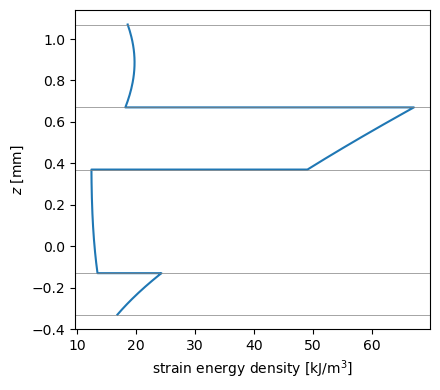

In [4]:
zs, dens = [], []
zk = zbot
for ply in lam.plies:
    C = np.asarray(ply.get_constitutive_matrix())
    for z in np.linspace(zk, zk + ply.h, 41):
        eps = e[0:3] + z*e[3:6] + z**3*e[6:9]
        gamma = e[9:11] + z**2*e[11:13]
        zs.append(z)
        dens.append(0.5*(eps @ C[:3, :3] @ eps + gamma @ C[3:, 3:] @ gamma))
    zk += ply.h
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(np.array(dens)/1e3, np.array(zs)*1e3)
for zi in zbot + np.cumsum([0] + [ply.h for ply in lam.plies]):
    ax.axhline(zi*1e3, color='gray', lw=0.5)
ax.set_xlabel('strain energy density [kJ/m$^3$]')
ax.set_ylabel('$z$ [mm]')
fig.tight_layout()
plt.show()

## References

1. Reddy, J. N., Mechanics of Laminated Composite Plates and Shells: Theory and Analysis, 2nd ed., CRC Press, 2003. https://doi.org/10.1201/b12409